In [1]:
import comparison_utils
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt

# class_label = 0

# sw2_matrix = np.load(f"../mini_sw/qcd_1k.npy")
# w2_matrix = np.load(f"../mini_w2/block_{class_label}_{class_label}.npy")

# num_queries = 1000
# n_neighbor = 100
# length = 1000

# avg_sim = comparison_utils.average_strict_jaccard(w2_matrix, sw2_matrix, n_neighbor)

# theoretical_avg_sim = n_neighbor / (length - 1)
# print(avg_sim)
# print(theoretical_avg_sim)

In [2]:
# [0.08735, 0.0953125, 0.0909, 0.0952250, 0.101025, 0.086875, 0.0902875, 0.094675]

In [3]:
# class_labels = np.arange(8)

# class_label = 0

# sw2_matrix = np.load(f"../mini_sw/block_{class_label}_{class_label}_sw2.npy")
# w2_matrix = np.load(f"../mini_w2/block_{class_label}_{class_label}.npy")

# avg_sims = np.zeros(n_neighbors.shape[0])

# for i, n_neighbor in tqdm(enumerate(n_neighbors), total=n_neighbors.shape[0]):
#     avg_sim = comparison_utils.average_strict_jaccard(w2_matrix, sw2_matrix, n_neighbor)
#     avg_sims[i] = avg_sim

In [4]:
# plt.plot(n_neighbors, avg_sims, label = 'Avg Sim')
# plt.plot(n_neighbors, theoretical_avg_sim, label = 'Theoretical Avg Sim')
# plt.xlabel('Num of Neighbors')
# plt.ylabel('Sim')
# plt.legend()
# plt.show()

100%|██████████| 200/200 [05:04<00:00,  1.52s/it]


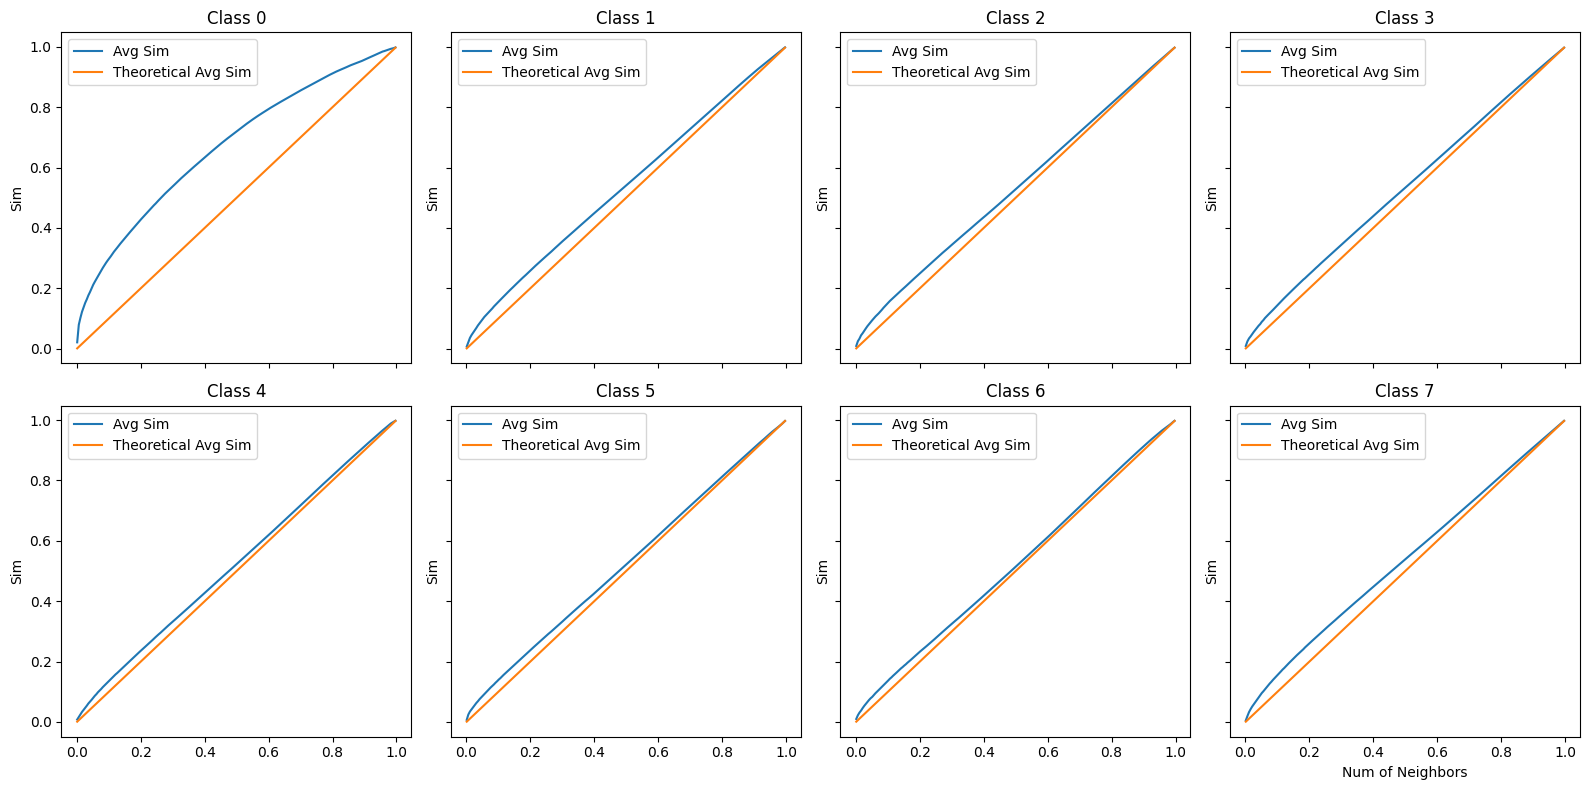

In [5]:
n_neighbors = np.arange(1, 999, 5)
length = 1000
theoretical_avg_sim = n_neighbors / (length - 1)
neighbor_percentage = np.arange(1/999, 1, 5/999)

class_labels = np.arange(8)

n_plots = len(class_labels)
ncols = 4
nrows = int(np.ceil(n_plots / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4*ncols, 4*nrows), sharex=True, sharey=True)
axes = axes.flatten()

avg_sims = np.zeros((n_plots, n_neighbors.size))

for ax, class_label in zip(axes, class_labels):
    sw2 = np.load(f"../mini_sw/block_{class_label}_{class_label}_sw2.npy")
    w2   = np.load(f"../mini_w2/block_{class_label}_{class_label}.npy")

    for i, n in tqdm(enumerate(n_neighbors), total=n_neighbors.size):
        avg_sims[class_label][i] = comparison_utils.average_strict_jaccard(w2, sw2, n)

    ax.plot(neighbor_percentage, avg_sims[class_label], label='Avg Sim')
    ax.plot(neighbor_percentage, theoretical_avg_sim, label='Theoretical Avg Sim')
    ax.set_title(f'Class {class_label}')
    ax.set_ylabel('Sim')
    ax.legend()
    
# common X-axis label on bottom
axes[-1].set_xlabel('Num of Neighbors')


plt.tight_layout()
plt.show()
# for class_label in class_labels:
#     sw2_matrix = np.load(f"../mini_sw/block_{class_label}_{class_label}_sw2.npy")
#     w2_matrix = np.load(f"../mini_w2/block_{class_label}_{class_label}.npy")

#     avg_sims = np.zeros(n_neighbors.shape[0])

#     for i, n_neighbor in tqdm(enumerate(n_neighbors), total=n_neighbors.shape[0]):
#         avg_sim = comparison_utils.average_strict_jaccard(w2_matrix, sw2_matrix, n_neighbor)
#         avg_sims[i] = avg_sim
        
#     plt.plot(n_neighbors, avg_sims, label = 'Avg Sim')
#     plt.plot(n_neighbors, theoretical_avg_sim, label = 'Theoretical Avg Sim')
#     plt.xlabel('Num of Neighbors')
#     plt.ylabel('Sim')
#     plt.legend()
#     plt.show()

In [6]:
avg_sims

array([[0.021     , 0.07916667, 0.10181818, ..., 0.99424239, 0.995667  ,
        0.99792269],
       [0.007     , 0.021     , 0.03563636, ..., 0.98948073, 0.99400706,
        0.99797289],
       [0.009     , 0.02466667, 0.03318182, ..., 0.98837221, 0.99282139,
        0.99700502],
       ...,
       [0.007     , 0.0245    , 0.03454545, ..., 0.98700507, 0.99193037,
        0.99698795],
       [0.01      , 0.02216667, 0.031     , ..., 0.98880933, 0.99357921,
        0.99749699],
       [0.005     , 0.01933333, 0.03254545, ..., 0.98838337, 0.99310091,
        0.99756827]])

In [15]:
from scipy.integrate import simpson

aucs_scipy = np.zeros(len(class_labels))
for i in range(len(class_labels)):
    aucs_scipy[i] = simpson(y=avg_sims[i], x=neighbor_percentage)
    
print(np.round(aucs_scipy, 3))

aucs_numpy = np.zeros(len(class_labels))
for i in range(len(class_labels)):
    aucs_numpy[i] = np.trapz(y=avg_sims[i], x=neighbor_percentage)
print(np.round(aucs_numpy, 3))

[0.666 0.534 0.525 0.527 0.52  0.519 0.516 0.532]
[0.666 0.534 0.525 0.527 0.52  0.519 0.516 0.532]
